# PLA FD I DoE Notebook

Fractional-factorial design, measurements, repeatability, mass, volume, density, regression, ANOVA, and interaction analysis for the PLA FD I series.


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from pla_doe_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS,
    FD_I_LEVELS,
    FD_II_LEVELS,
    IRONING_FIXED_SETTINGS,
    IRONING_LEVELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_CONFIRMATION_RUNS,
    IRONING_STRINGING_RUNS,
    IRONING_REPEAT_STRINGING_RUNS,
    IRONING_REPEAT_BLOB_COUNTS,
    IRONING_BLOB_COUNTS,
    IRONING_REPEAT_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_HYDROSTATIC_MEASUREMENTS,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_HYDROSTATIC_MEASUREMENTS,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_RUNS,
    FD_II_CONCENTRIC_RUN_LABELS,
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
)
from DoE_old_scale import (
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    FD_I_OLD_SCALE_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    FACTOR_COLORS,
    build_mass_measurements,
    build_response_measurements,
    build_factor_level_coverage,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    build_screening_confirmation_comparison,
    plot_mass_quality_tradeoff,
    plot_quality_counts,
    build_mass_quality_tradeoff,
    plot_desirability_ranking,
    build_desirability_table,
    build_ironing_quality_table,
    build_model_anova_table,
    build_term_significance_table,
    build_error_comparison_table,
    build_quadratic_anova_table,
    volume_cm3,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_center_curvature,
    calculate_repeatability,
    calculate_pure_error_from_replicates,
    calculate_measurement_error_from_repeated_columns,
    calculate_score_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    format_quadratic_model_formula,
    fit_main_effect_screening_model,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_model_anova,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_screening_response_contours,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_screening_model_effects,
    plot_combined_screening_model_effects,
    plot_screening_observed_vs_predicted,
    plot_augmented_model_pareto,
    plot_augmented_main_effects,
    plot_augmented_observed_vs_predicted,
    plot_augmented_residuals,
    plot_screening_half_normal,
    plot_mass_measurements,
    plot_response_measurements,
    plot_combined_mass_measurement_sets,
    plot_center_point_repeatability,
    plot_center_curvature,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
    plot_interaction_mean_matrix,
)
from notebook_plot_saver import configure_notebook_plot_saving

PLOT_OUTPUT_ROOT = configure_notebook_plot_saving("notebook_figures")
print(f"Notebook figures will be saved under: {PLOT_OUTPUT_ROOT}")

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


Notebook figures will be saved under: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


In [2]:
DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


## 1) DoE Matrix


### FD_I Screening Matrix With Wall Factors


In [3]:
fd_I_coded_df = create_fractional_factorial_design(include_walls=True)
fd_I_real_df = map_coded_to_real(fd_I_coded_df, FD_I_LEVELS)

fd_I_coded_display = fd_I_coded_df.rename(columns=DISPLAY_NAMES).reset_index()
fd_I_real_display = fd_I_real_df.rename(columns=DISPLAY_NAMES).reset_index()

display(fd_I_coded_display)
#display(fd_I_real_display)


,Run,Flow Ratio (-),Nozzle Temp (deg C),Print Speed (mm/s),Line Width (mm),Layer Height (mm),Walls (-)
0,1,-1,-1,-1,-1,1,1
1,2,-1,-1,-1,1,1,1
2,3,-1,-1,1,-1,1,-1
3,4,-1,-1,1,1,1,-1
4,5,-1,1,-1,-1,-1,1
5,6,-1,1,-1,1,-1,1
6,7,-1,1,1,-1,-1,-1
7,8,-1,1,1,1,-1,-1
8,9,1,-1,-1,-1,-1,-1
9,10,1,-1,-1,1,-1,-1


In [4]:
#style_low_high(fd_I_real_df, FD_I_LEVELS)


In [5]:
rep2 = randomized_second_run_order(random_state=123)
#rep2


## 2) Measurements


### FD_I Mass Measurements


In [6]:
fd_I_mass_measurements_g, fd_I_mass_columns = build_mass_measurements(
    FD_I_MASS_MEASUREMENTS_G,
    run_prefix="R",
)
fd_I_repeat_mass_measurements_g, fd_I_repeat_mass_columns = build_repeat_mass_measurements(
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
)

display(fd_I_mass_measurements_g[["run", *fd_I_mass_columns, "mass_mean_g", "mass_std_g"]])
display(fd_I_repeat_mass_measurements_g[["run", *fd_I_repeat_mass_columns, "mass_mean_g", "mass_std_g"]])


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,R1,13.681,13.505,13.6,0.124451
1,R2,13.657,13.480,13.6,0.125158
2,R3,13.622,13.444,13.5,0.125865
3,R4,13.594,13.414,13.5,0.127279
4,R5,13.796,13.621,13.7,0.123744
5,R6,13.843,13.664,13.8,0.126572
6,R7,13.972,13.793,13.9,0.126572
7,R8,13.973,13.795,13.9,0.125865
8,R9,14.480,14.300,14.4,0.127279
9,R10,14.541,14.357,14.4,0.130108


,run,mass_1_g,mass_mean_g,mass_std_g
0,R2.2,13.795,13.8,NaN
1,R9.2,14.555,14.6,NaN
2,R12.2,14.628,14.6,NaN


#### FD_I Mass Change Between Measurements

This table compares the first FD_I new-scale measurement with the July measurement. `mass_loss_g = mass_1_g - mass_2_g`, so positive values mean the specimen measured lighter in July. This could indicate drying or another systematic scale/handling difference.

In [7]:
fd_I_mass_change_g = fd_I_mass_measurements_g[["run", "mass_1_g", "mass_2_g"]].copy()
fd_I_mass_change_g["mass_loss_g"] = (
    fd_I_mass_change_g["mass_1_g"] - fd_I_mass_change_g["mass_2_g"]
)
fd_I_mass_change_g["mass_loss_percent"] = (
    fd_I_mass_change_g["mass_loss_g"] / fd_I_mass_change_g["mass_1_g"] * 100
)

fd_I_average_mass_loss = pd.DataFrame({
    "specimen_count": [fd_I_mass_change_g["mass_loss_g"].notna().sum()],
    "average_mass_loss_g": [fd_I_mass_change_g["mass_loss_g"].mean()],
    "average_mass_loss_percent": [fd_I_mass_change_g["mass_loss_percent"].mean()],
    "min_mass_loss_g": [fd_I_mass_change_g["mass_loss_g"].min()],
    "max_mass_loss_g": [fd_I_mass_change_g["mass_loss_g"].max()],
})

display(fd_I_mass_change_g.round({
    "mass_1_g": 3,
    "mass_2_g": 3,
    "mass_loss_g": 3,
    "mass_loss_percent": 2,
}))
display(fd_I_average_mass_loss.round({
    "average_mass_loss_g": 3,
    "average_mass_loss_percent": 2,
    "min_mass_loss_g": 3,
    "max_mass_loss_g": 3,
}))


,run,mass_1_g,mass_2_g,mass_loss_g,mass_loss_percent
0,R1,13.681,13.505,0.176,1.29
1,R2,13.657,13.480,0.177,1.30
2,R3,13.622,13.444,0.178,1.31
3,R4,13.594,13.414,0.180,1.32
4,R5,13.796,13.621,0.175,1.27
5,R6,13.843,13.664,0.179,1.29
6,R7,13.972,13.793,0.179,1.28
7,R8,13.973,13.795,0.178,1.27
8,R9,14.480,14.300,0.180,1.24
9,R10,14.541,14.357,0.184,1.27


,specimen_count,average_mass_loss_g,average_mass_loss_percent,min_mass_loss_g,max_mass_loss_g
0,16,0.18,1.27,0.175,0.184


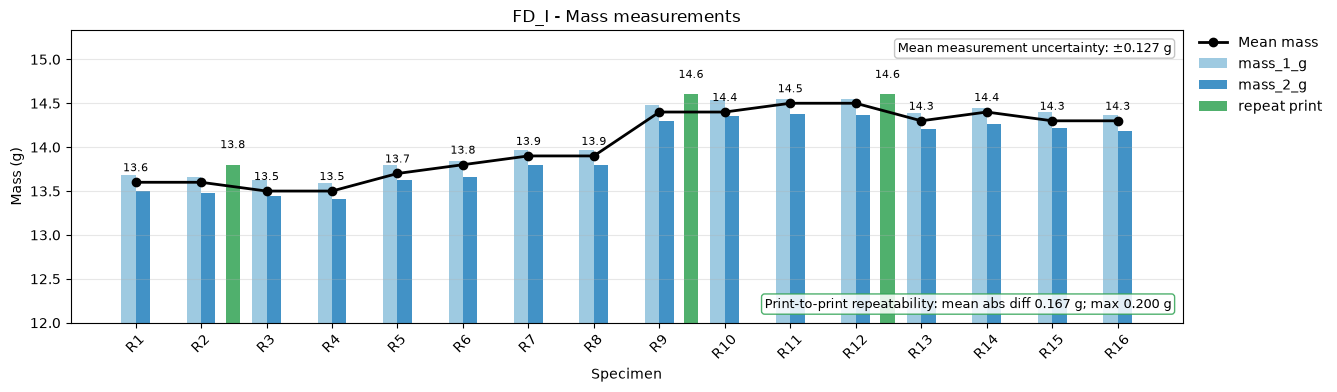

In [8]:
plot_mass_measurements(
    fd_I_mass_measurements_g,
    fd_I_mass_columns,
    y_min=12,
    mean_label="Mean mass",
    experiment="FD_I",
    repeat_measurements_g=fd_I_repeat_mass_measurements_g,
)


#### FD_I Hydrostatic Measurements

These values come from the air/water weighing sheet. Volume is calculated from the buoyancy difference, density is mass divided by volume, and percentage is the relative density compared with the PLA material density.

In [9]:
fd_I_hydrostatic_tables = {}
fd_I_hydrostatic_columns = {}

for response_name, measurements in FD_I_HYDROSTATIC_MEASUREMENTS.items():
    mean_digits = 1 if response_name == "relative_density_percent" else 3
    table, columns = build_response_measurements(
        measurements,
        run_prefix="R",
        response_name=response_name,
        mean_round_digits=mean_digits,
    )
    fd_I_hydrostatic_tables[response_name] = table
    fd_I_hydrostatic_columns[response_name] = columns

fd_I_hydrostatic_summary = fd_I_hydrostatic_tables["weight_in_air_g"][["run"]].copy()
for response_name, table in fd_I_hydrostatic_tables.items():
    fd_I_hydrostatic_summary[f"{response_name}_mean"] = table[f"{response_name}_mean"]
    fd_I_hydrostatic_summary[f"{response_name}_std"] = table[f"{response_name}_std"]

display(fd_I_hydrostatic_summary.round({
    "weight_in_air_g_mean": 3,
    "weight_in_air_g_std": 3,
    "weight_in_water_g_mean": 3,
    "weight_in_water_g_std": 3,
    "volume_cm3_mean": 3,
    "volume_cm3_std": 3,
    "density_g_cm3_mean": 3,
    "density_g_cm3_std": 3,
    "relative_density_percent_mean": 1,
    "relative_density_percent_std": 2,
}))


,run,weight_in_air_g_mean,weight_in_air_g_std,weight_in_water_g_mean,weight_in_water_g_std,volume_cm3_mean,volume_cm3_std,density_g_cm3_mean,density_g_cm3_std,relative_density_percent_mean,relative_density_percent_std
0,R1,13.360,0.014,10.170,0.028,10.190,0.028,1.310,0.000,98.2,0.4
1,R2,13.340,0.014,10.175,0.021,10.195,0.021,1.310,0.000,98.0,0.4
2,R3,13.305,0.007,10.140,0.000,10.160,0.000,1.310,0.000,98.2,0.1
3,R4,13.255,0.035,10.150,0.000,10.170,0.000,1.305,0.007,97.7,0.3
4,R5,13.470,0.014,10.365,0.007,10.385,0.007,1.300,0.000,97.2,0.0
5,R6,13.510,0.028,10.350,0.014,10.370,0.014,1.305,0.007,97.6,0.4
6,R7,13.655,0.007,10.320,0.000,10.340,0.000,1.320,0.000,99.0,0.1
7,R8,13.635,0.021,10.325,0.021,10.345,0.021,1.315,0.007,98.8,0.4
8,R9,14.135,0.021,10.640,0.000,10.660,0.000,1.325,0.007,99.4,0.1
9,R10,14.190,0.014,10.605,0.106,10.625,0.106,1.335,0.007,100.1,0.9


#### FD_I Hydrostatic Volume and Density Plots

These plots use the same repeated air/water measurements as the table above. They are shown separately from mass because volume and density answer different questions: volume shows specimen geometry, while density shows compactness of the printed material.


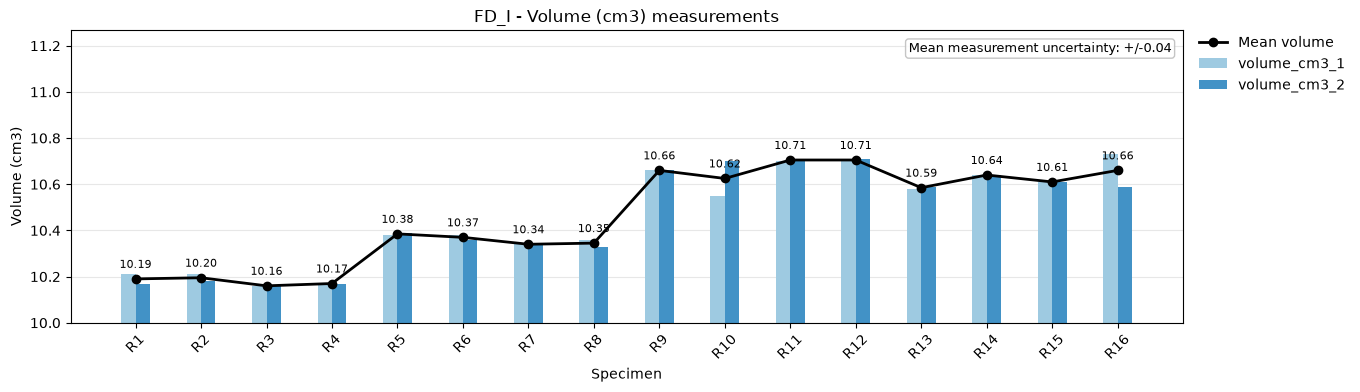

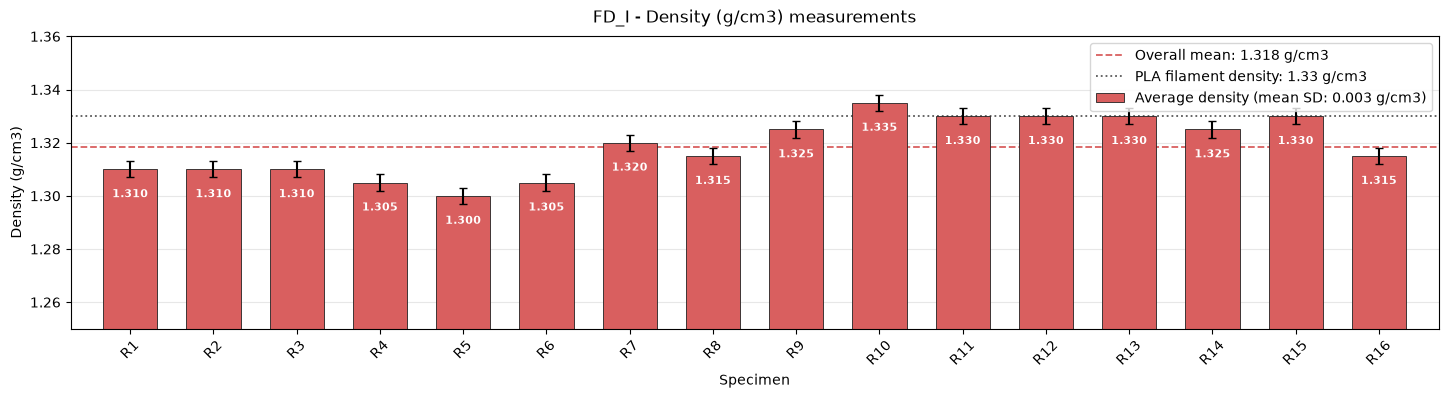

In [10]:
plot_response_measurements(
    fd_I_hydrostatic_tables["volume_cm3"],
    fd_I_hydrostatic_columns["volume_cm3"],
    response_name="volume_cm3",
    y_label="Volume (cm3)",
    y_min=10,
    mean_label="Mean volume",
    experiment="FD_I",
    value_digits=2,
)

plot_response_measurements(
    fd_I_hydrostatic_tables["density_g_cm3"],
    fd_I_hydrostatic_columns["density_g_cm3"],
    response_name="density_g_cm3",
    y_label="Density (g/cm3)",
    y_min=1.25,
    y_max=1.36,
    mean_label="Average density",
    experiment="FD_I",
    value_digits=3,
    average_bars_only=True,
    average_bar_color="#d95f5f",
    show_overall_mean=True,
    overall_mean_color="#d95f5f",
    reference_value=1.33,
    reference_label="PLA filament density: 1.33 g/cm3",
    average_labels_inside=True,
    use_mean_sd_errorbars=True,
    title_pad=10,
)


#### FD_I Weight, Volume, and Density Correlations

These scatter plots check whether the measured responses move together. 
The first three plots use the precision-scale `mass_mean_g` together with the hydrostatic volume and density values. 
The final plot compares the precision-scale mass with the average `weight_in_air_g` used for the Archimedes density calculation.

The Pearson correlation `r` describes linear correlation: values close to +1 increase together, values close to -1 move in opposite directions, and values close to 0 show little linear correlation.


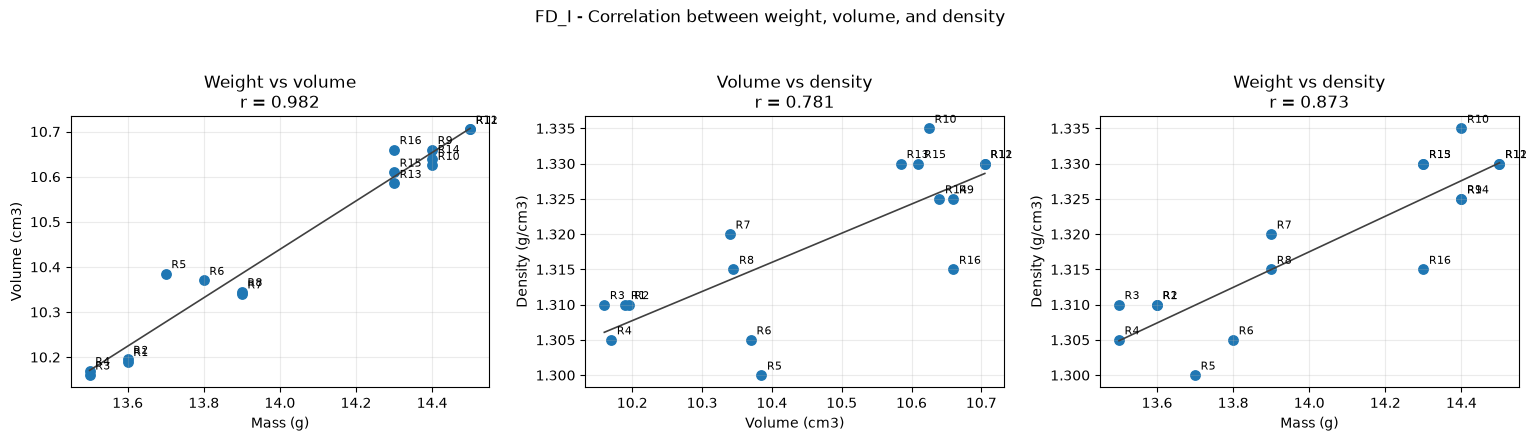

,run,mass_mean_g,volume_cm3_mean,density_g_cm3_mean,archimedes_weight_in_air_g
0,R1,13.6,10.190,1.310,13.360
1,R2,13.6,10.195,1.310,13.340
2,R3,13.5,10.160,1.310,13.305
3,R4,13.5,10.170,1.305,13.255
4,R5,13.7,10.385,1.300,13.470
5,R6,13.8,10.370,1.305,13.510
6,R7,13.9,10.340,1.320,13.655
7,R8,13.9,10.345,1.315,13.635
8,R9,14.4,10.660,1.325,14.135
9,R10,14.4,10.625,1.335,14.190


,comparison,n,pearson_r
0,Weight vs volume,16,0.982
1,Volume vs density,16,0.781
2,Weight vs density,16,0.873


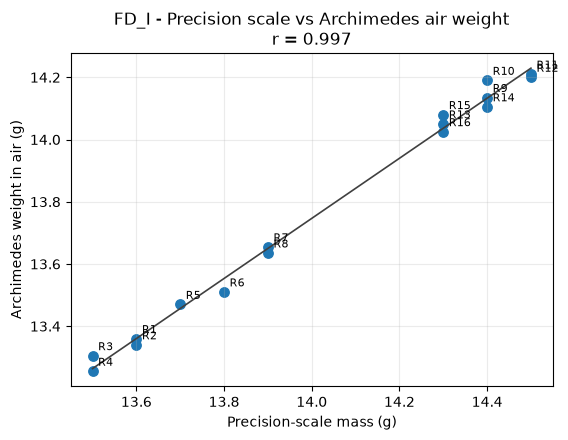

,run,mass_mean_g,archimedes_weight_in_air_g
0,R1,13.6,13.360
1,R2,13.6,13.340
2,R3,13.5,13.305
3,R4,13.5,13.255
4,R5,13.7,13.470
5,R6,13.8,13.510
6,R7,13.9,13.655
7,R8,13.9,13.635
8,R9,14.4,14.135
9,R10,14.4,14.190


,comparison,n,pearson_r
0,Precision-scale mass vs Archimedes air weight,16,0.997


Rank change compares heaviest-to-lightest order. 0 means the plate has the same rank in both measurements; positive means it ranks lighter in the Archimedes air-weight order; negative means it ranks heavier.


,run,mass_mean_g,archimedes_weight_in_air_g,precision_rank_heavy_to_light,archimedes_rank_heavy_to_light,rank_change,same_order_position
1,R2,13.6,13.340,13,14,1,False
3,R4,13.5,13.255,15,16,1,False
7,R8,13.9,13.635,9,10,1,False
8,R9,14.4,14.135,3,4,1,False
11,R12,14.5,14.200,1,2,1,False
12,R13,14.3,14.050,6,7,1,False
13,R14,14.4,14.105,3,5,2,False
15,R16,14.3,14.025,6,8,2,False
0,R1,13.6,13.360,13,13,0,True
2,R3,13.5,13.305,15,15,0,True


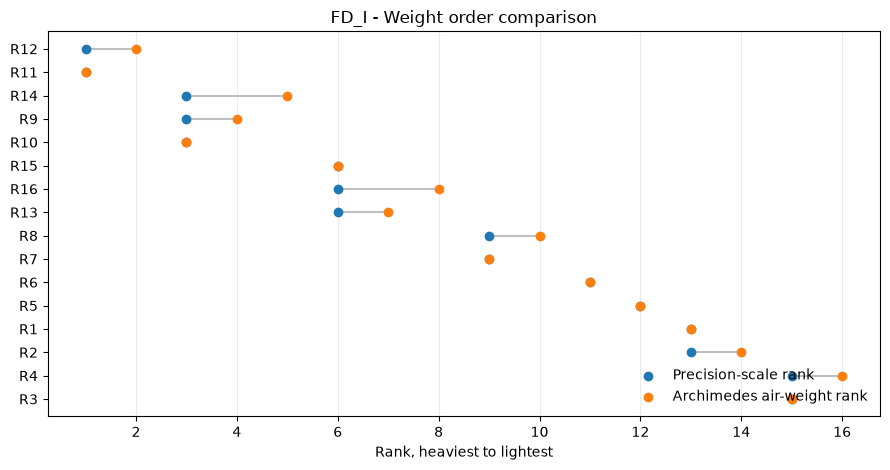

In [11]:
import matplotlib.pyplot as plt
import numpy as np

fd_I_correlation_data = (
    fd_I_mass_measurements_g[["run", "mass_mean_g"]]
    .merge(
        fd_I_hydrostatic_tables["volume_cm3"][["run", "volume_cm3_mean"]],
        on="run",
        how="inner",
    )
    .merge(
        fd_I_hydrostatic_tables["density_g_cm3"][["run", "density_g_cm3_mean"]],
        on="run",
        how="inner",
    )
    .merge(
        fd_I_hydrostatic_tables["weight_in_air_g"][["run", "weight_in_air_g_mean"]],
        on="run",
        how="inner",
    )
    .rename(columns={"weight_in_air_g_mean": "archimedes_weight_in_air_g"})
)

correlation_pairs = [
    ("mass_mean_g", "volume_cm3_mean", "Mass (g)", "Volume (cm3)", "Weight vs volume"),
    ("volume_cm3_mean", "density_g_cm3_mean", "Volume (cm3)", "Density (g/cm3)", "Volume vs density"),
    ("mass_mean_g", "density_g_cm3_mean", "Mass (g)", "Density (g/cm3)", "Weight vs density"),
]

fd_I_correlation_summary = []
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, correlation_pairs):
    plot_df = fd_I_correlation_data[["run", x_col, y_col]].dropna()
    r_value = plot_df[x_col].corr(plot_df[y_col])
    fd_I_correlation_summary.append({
        "comparison": title,
        "n": len(plot_df),
        "pearson_r": r_value,
    })

    ax.scatter(plot_df[x_col], plot_df[y_col], color="#1f77b4", s=46)
    for _, row in plot_df.iterrows():
        ax.annotate(
            row["run"],
            (row[x_col], row[y_col]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    if len(plot_df) >= 2:
        slope, intercept = np.polyfit(plot_df[x_col], plot_df[y_col], 1)
        x_line = np.linspace(plot_df[x_col].min(), plot_df[x_col].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)

    ax.set_title(f"{title}\nr = {r_value:.3f}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)

fig.suptitle("FD_I - Correlation between weight, volume, and density", y=1.04)
plt.tight_layout()
plt.show(block=False)

display(fd_I_correlation_data.round({
    "mass_mean_g": 3,
    "volume_cm3_mean": 3,
    "density_g_cm3_mean": 3,
}))
display(pd.DataFrame(fd_I_correlation_summary).round({"pearson_r": 3}))


archimedes_precision_df = fd_I_correlation_data[[
    "run",
    "mass_mean_g",
    "archimedes_weight_in_air_g",
]].dropna()
archimedes_precision_r = archimedes_precision_df["mass_mean_g"].corr(
    archimedes_precision_df["archimedes_weight_in_air_g"]
)

fig, ax = plt.subplots(figsize=(5.8, 4.5))
ax.scatter(
    archimedes_precision_df["mass_mean_g"],
    archimedes_precision_df["archimedes_weight_in_air_g"],
    color="#1f77b4",
    s=46,
)
for _, row in archimedes_precision_df.iterrows():
    ax.annotate(
        row["run"],
        (row["mass_mean_g"], row["archimedes_weight_in_air_g"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )
if len(archimedes_precision_df) >= 2:
    slope, intercept = np.polyfit(
        archimedes_precision_df["mass_mean_g"],
        archimedes_precision_df["archimedes_weight_in_air_g"],
        1,
    )
    x_line = np.linspace(
        archimedes_precision_df["mass_mean_g"].min(),
        archimedes_precision_df["mass_mean_g"].max(),
        100,
    )
    ax.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)
ax.set_title(f"FD_I - Precision scale vs Archimedes air weight\nr = {archimedes_precision_r:.3f}")
ax.set_xlabel("Precision-scale mass (g)")
ax.set_ylabel("Archimedes weight in air (g)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show(block=False)

display(archimedes_precision_df.round({
    "mass_mean_g": 3,
    "archimedes_weight_in_air_g": 3,
}))
display(pd.DataFrame([{
    "comparison": "Precision-scale mass vs Archimedes air weight",
    "n": len(archimedes_precision_df),
    "pearson_r": archimedes_precision_r,
}]).round({"pearson_r": 3}))


fd_I_weight_rank_comparison = archimedes_precision_df.copy()
fd_I_weight_rank_comparison["precision_rank_heavy_to_light"] = (
    fd_I_weight_rank_comparison["mass_mean_g"]
    .rank(method="min", ascending=False)
    .astype(int)
)
fd_I_weight_rank_comparison["archimedes_rank_heavy_to_light"] = (
    fd_I_weight_rank_comparison["archimedes_weight_in_air_g"]
    .rank(method="min", ascending=False)
    .astype(int)
)
fd_I_weight_rank_comparison["rank_change"] = (
    fd_I_weight_rank_comparison["archimedes_rank_heavy_to_light"]
    - fd_I_weight_rank_comparison["precision_rank_heavy_to_light"]
)
fd_I_weight_rank_comparison["same_order_position"] = (
    fd_I_weight_rank_comparison["rank_change"] == 0
)
fd_I_weight_rank_comparison = fd_I_weight_rank_comparison.sort_values(
    ["same_order_position", "rank_change"],
    ascending=[True, True],
)

print(
    "Rank change compares heaviest-to-lightest order. "
    "0 means the plate has the same rank in both measurements; "
    "positive means it ranks lighter in the Archimedes air-weight order; "
    "negative means it ranks heavier."
)
display(fd_I_weight_rank_comparison[[
    "run",
    "mass_mean_g",
    "archimedes_weight_in_air_g",
    "precision_rank_heavy_to_light",
    "archimedes_rank_heavy_to_light",
    "rank_change",
    "same_order_position",
]].round({
    "mass_mean_g": 3,
    "archimedes_weight_in_air_g": 3,
}))

rank_plot_df = fd_I_weight_rank_comparison.sort_values("precision_rank_heavy_to_light")
fig, ax = plt.subplots(figsize=(9, 4.8))
y_positions = np.arange(len(rank_plot_df))
ax.hlines(
    y_positions,
    rank_plot_df["precision_rank_heavy_to_light"],
    rank_plot_df["archimedes_rank_heavy_to_light"],
    color="0.75",
    linewidth=1.5,
)
ax.scatter(
    rank_plot_df["precision_rank_heavy_to_light"],
    y_positions,
    color="#1f77b4",
    label="Precision-scale rank",
    zorder=3,
)
ax.scatter(
    rank_plot_df["archimedes_rank_heavy_to_light"],
    y_positions,
    color="#ff7f0e",
    label="Archimedes air-weight rank",
    zorder=3,
)
ax.set_yticks(y_positions)
ax.set_yticklabels(rank_plot_df["run"])
ax.invert_yaxis()
ax.set_xlabel("Rank, heaviest to lightest")
ax.set_title("FD_I - Weight order comparison")
ax.grid(axis="x", alpha=0.25)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show(block=False)


#### FD_I Old-Scale Mass Measurements

This comparison uses the archived old-scale FD_I measurements. The same mass helper is used here: if four measurements are available it drops the lowest and highest values and averages the middle two; with the two archived FD_I measurements it averages both values.

,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,R1,12.907,13.272,13.1,0.258094
1,R2,13.334,13.296,13.3,0.026870
2,R3,13.294,13.286,13.3,0.005657
3,R4,13.259,13.240,13.2,0.013435
4,R5,13.454,13.432,13.4,0.015556
5,R6,13.490,13.448,13.5,0.029698
6,R7,13.622,13.492,13.6,0.091924
7,R8,13.637,13.595,13.6,0.029698
8,R9,14.136,14.126,14.1,0.007071
9,R10,14.188,14.173,14.2,0.010607


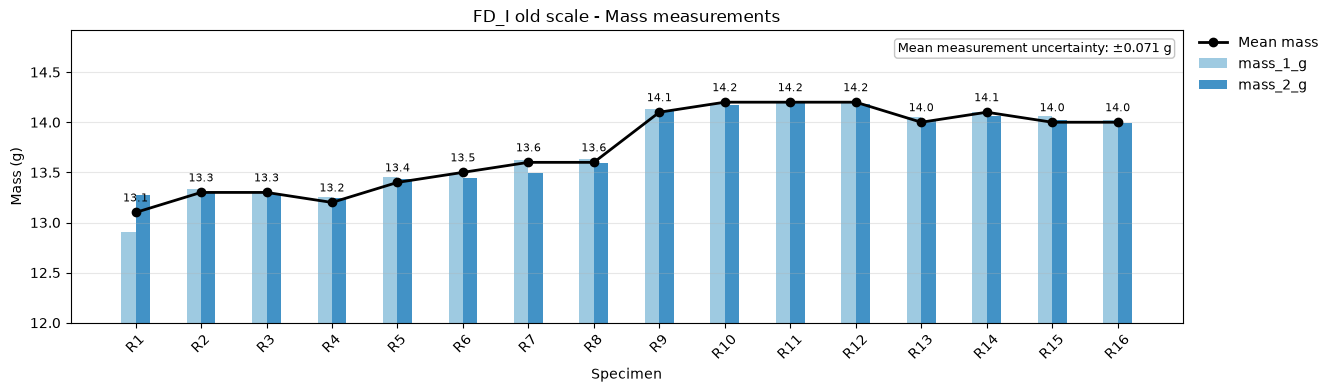

In [12]:
fd_I_old_scale_mass_measurements_g, fd_I_old_scale_mass_columns = build_mass_measurements(
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    run_prefix="R",
)
display(fd_I_old_scale_mass_measurements_g[[
    "run",
    *fd_I_old_scale_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    fd_I_old_scale_mass_measurements_g,
    fd_I_old_scale_mass_columns,
    y_min=12,
    mean_label="Mean mass",
    experiment="FD_I old scale",
)


#### FD_I Repeatability From Repeated Prints


In [13]:
fd_I_repeatability = calculate_repeatability(
    fd_I_mass_measurements_g,
    fd_I_repeat_mass_measurements_g,
)

display(fd_I_repeatability)
print(
    "Mean absolute repeat difference:",
    f"{fd_I_repeatability['abs_difference_g'].mean():.3f} g",
)


,run_repeat,original_run,original_mass_mean_g,repeat_mass_mean_g,repeat_print_count,difference_g,abs_difference_g,difference_percent
0,R12 repeat print,R12,14.5,14.6,1,0.1,0.1,0.69
1,R2 repeat print,R2,13.6,13.8,1,0.2,0.2,1.47
2,R9 repeat print,R9,14.4,14.6,1,0.2,0.2,1.39


Mean absolute repeat difference: 0.167 g


## 3) Analysis


### FD_I Screening Analysis


#### FD_I Main-Effect Estimates


In [14]:
mass_result_matrix_I = build_result_matrix(
    fd_I_coded_df,
    fd_I_mass_measurements_g,
    response="mass_mean_g",
)

main_effect_df_I = compute_main_effects(mass_result_matrix_I)
main_effect_df_I


,Effect,Main effect
0,A_flow_ratio,7.000000e-01
1,B_nozzle_temp,7.500000e-02
2,C_speed,2.500000e-02
3,D_line_width,2.500000e-02
4,E_layer_height,-2.000000e-01
5,F_walls,1.776357e-15


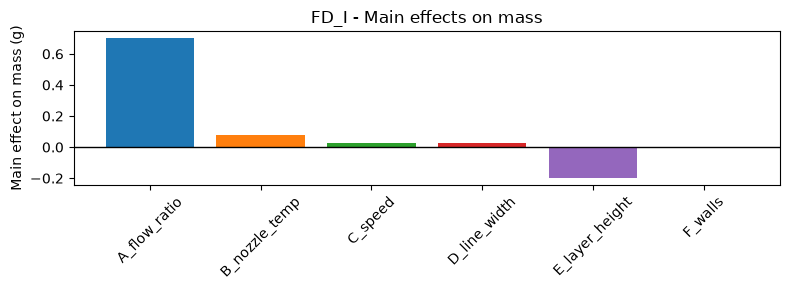

In [15]:
plot_main_effects_bar(
    main_effect_df_I,
    response="mass_mean_g",
    experiment="FD_I",
)


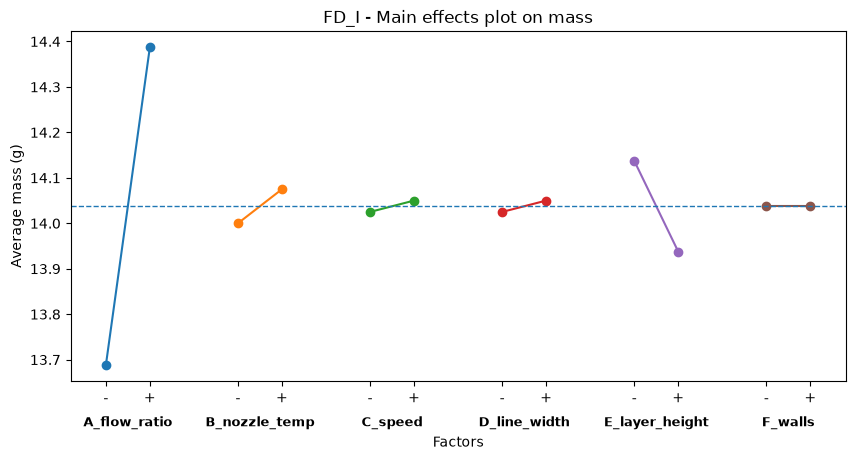

In [16]:
plot_main_effects_line(
    mass_result_matrix_I,
    response="mass_mean_g",
    experiment="FD_I",
)


#### FD_I Regression Main-Effects Plot


This regression-style FD_I analysis fits one main-effects model for each response: mass, hydrostatic volume, and bulk density. 
For the balanced FD_I matrix, the fitted low/high trends match the ordinary main-effect estimates, but the regression model also gives coefficient standard errors, t values, p values, ANOVA tables, and alpha-threshold Pareto charts.


#### Regression term significance and repeatability

The Pareto chart shows which effects are large compared with the estimated uncertainty. Terms above the alpha = 0.05 threshold are considered statistically significant for this screening experiment. Terms below the threshold should not be interpreted as statistically confirmed, but they may still be practically relevant if they affect print quality.

Repeated scale readings such as `mass_1_g` and `mass_2_g` are measurement repeats of the same printed specimen, so they estimate measurement uncertainty, not independent print-to-print error. Actual repeated prints with identical settings are used for replicate-based pure error. For hydrostatic volume and density, the current repeated readings provide a measurement-based threshold; a true replicate-based threshold would require repeated hydrostatic measurements on repeated prints at the same settings.

The solid threshold uses the regression residual degrees of freedom. A dashed threshold uses print-replicate pure-error degrees of freedom when available. A dotted threshold uses repeated-measurement degrees of freedom when repeated readings are available for that response.


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,7,7,True,9,0.9772,0.0745


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
1,A_flow_ratio=-1|B_nozzle_temp=-1|C_speed=-1|D_...,2,13.70,0.020,1
8,A_flow_ratio=1|B_nozzle_temp=-1|C_speed=-1|D_l...,2,14.50,0.020,1
11,A_flow_ratio=1|B_nozzle_temp=-1|C_speed=1|D_li...,2,14.55,0.005,1


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,3,6,0.045,3,0.015,0.1225


,error_basis,SS,df,MSE,s
0,regression residual,0.050,9.0,0.0056,0.0745
1,replicate pure error,0.045,3.0,0.0150,0.1225


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,6,2.1475,0.3579,64.425,0.0
1,Residual,9,0.0500,0.0056,NaN,NaN
2,Total,15,2.1975,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.3500,0.0186,18.7830,352.80,0.0000,0.0306,11.4310,130.6667,0.0014,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0375,0.0186,2.0125,4.05,0.0750,0.0306,1.2247,1.5000,0.3081,NaN,NaN,NaN,NaN
3,C_speed,0.0125,0.0186,0.6708,0.45,0.5192,0.0306,0.4082,0.1667,0.7105,NaN,NaN,NaN,NaN
4,D_line_width,0.0125,0.0186,0.6708,0.45,0.5192,0.0306,0.4082,0.1667,0.7105,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1000,0.0186,-5.3666,28.80,0.0005,0.0306,-3.2660,10.6667,0.0469,NaN,NaN,NaN,NaN
6,F_walls,0.0000,0.0186,0.0000,0.00,1.0000,0.0306,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN


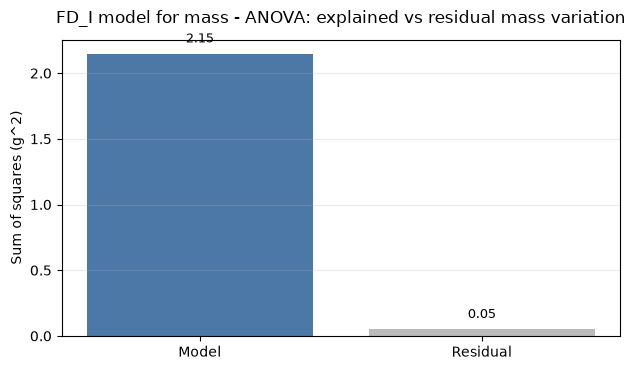

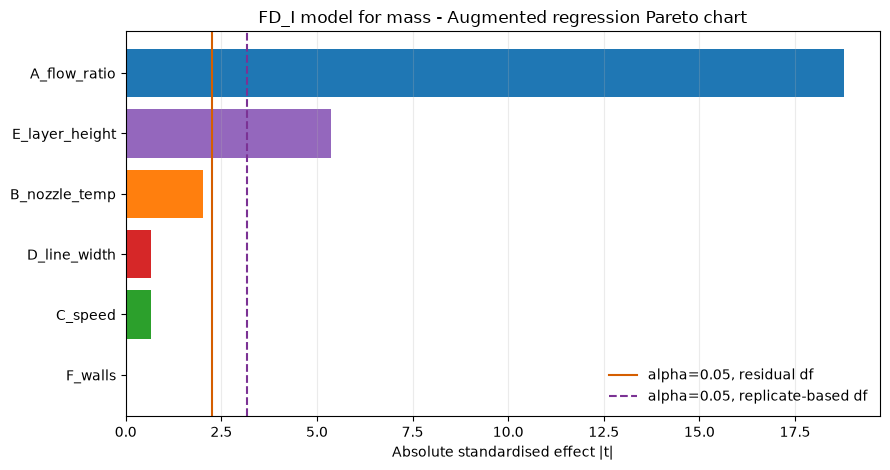

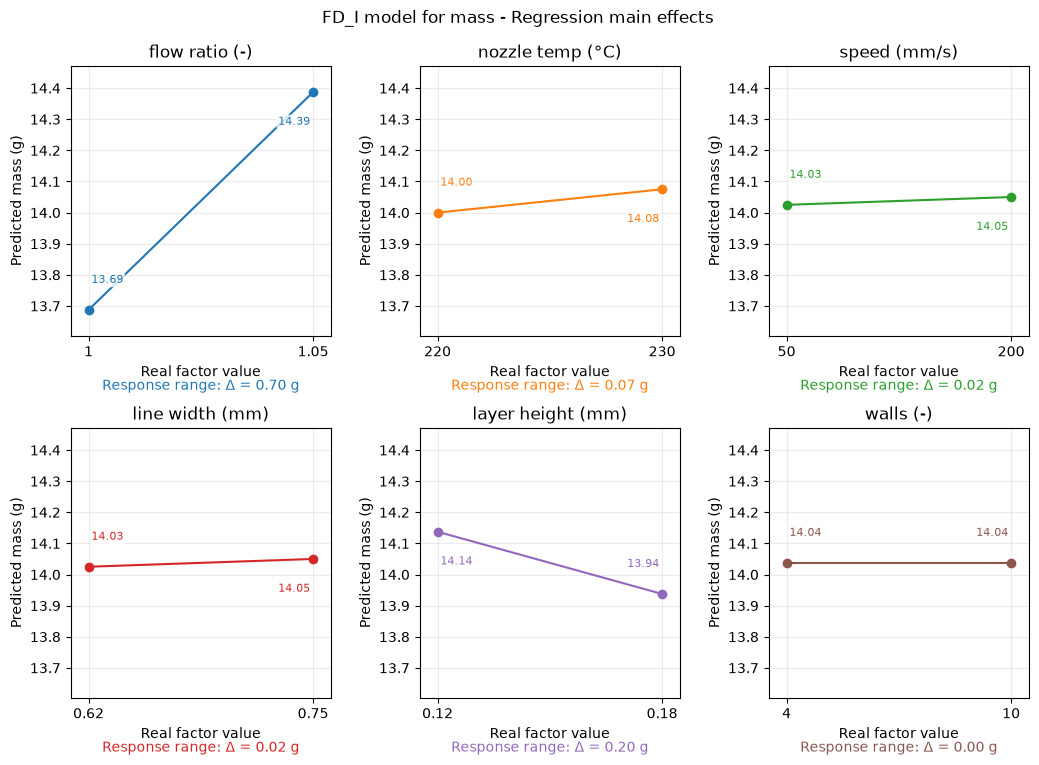

,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,6,0.6523,0.1087,242.2549,0.0
1,Residual,9,0.0040,0.0004,NaN,NaN
2,Total,15,0.6564,NaN,NaN,NaN


,run,n_group,group_mean,SS_measurement_group,df_measurement_group
0,R1,2,10.190,0.0008,1
1,R10,2,10.625,0.0112,1
2,R11,2,10.705,0.0001,1
3,R12,2,10.705,0.0001,1
4,R13,2,10.585,0.0000,1
5,R14,2,10.640,0.0000,1
6,R15,2,10.610,0.0000,1
7,R16,2,10.660,0.0098,1
8,R2,2,10.195,0.0005,1
9,R3,2,10.160,0.0000,1


,measurement_groups,measurement_observations,SS_measurement,df_measurement,MSE_measurement,s_measurement
0,16,32,0.0231,16,0.0014,0.038


,error_basis,SS,df,MSE,s
0,regression residual,0.0040,9.0,0.0004,0.0212
1,measurement repeatability,0.0231,16.0,0.0014,0.0380


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.1897,0.0053,35.8162,1282.8012,0.0000,NaN,NaN,NaN,NaN,0.0095,19.9473,397.8931,0.0000
2,B_nozzle_temp,0.0328,0.0053,6.1956,38.3849,0.0002,NaN,NaN,NaN,NaN,0.0095,3.4505,11.9060,0.0033
3,C_speed,0.0028,0.0053,0.5310,0.2820,0.6082,NaN,NaN,NaN,NaN,0.0095,0.2958,0.0875,0.7712
4,D_line_width,0.0047,0.0053,0.8851,0.7834,0.3991,NaN,NaN,NaN,NaN,0.0095,0.4929,0.2430,0.6288
5,E_layer_height,-0.0578,0.0053,-10.9160,119.1586,0.0000,NaN,NaN,NaN,NaN,0.0095,-6.0795,36.9600,0.0000
6,F_walls,0.0184,0.0053,3.4813,12.1195,0.0069,NaN,NaN,NaN,NaN,0.0095,1.9389,3.7592,0.0704


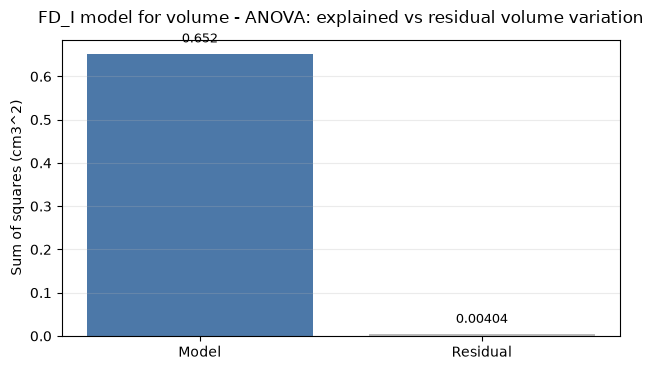

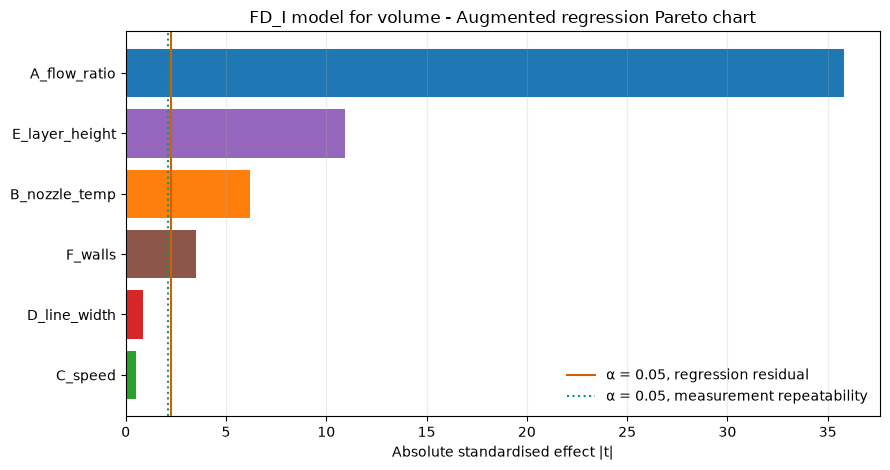

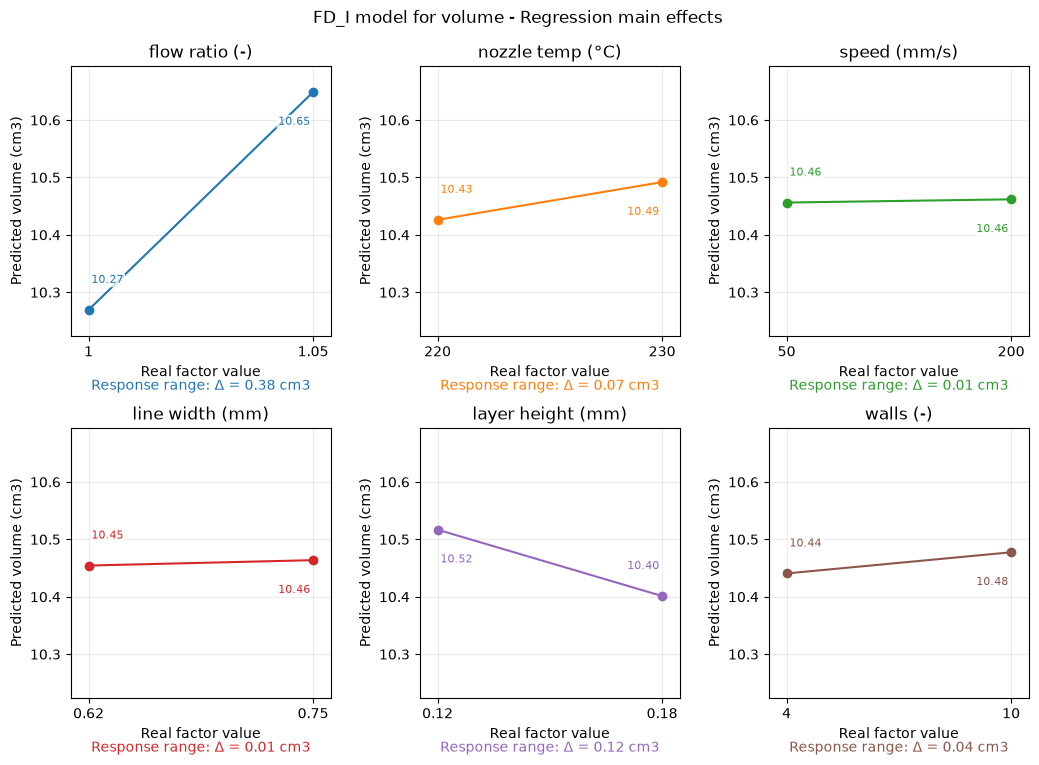

,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,6,0.0015,0.0002,6.0644,0.0086
1,Residual,9,0.0004,0.0000,NaN,NaN
2,Total,15,0.0018,NaN,NaN,NaN


,run,n_group,group_mean,SS_measurement_group,df_measurement_group
0,R1,2,1.310,0.0000,1
1,R10,2,1.335,0.0001,1
2,R11,2,1.330,0.0000,1
3,R12,2,1.330,0.0000,1
4,R13,2,1.330,0.0000,1
5,R14,2,1.325,0.0001,1
6,R15,2,1.330,0.0000,1
7,R16,2,1.315,0.0001,1
8,R2,2,1.310,0.0000,1
9,R3,2,1.310,0.0000,1


,measurement_groups,measurement_observations,SS_measurement,df_measurement,MSE_measurement,s_measurement
0,16,32,0.0004,16,0.0,0.0047


,error_basis,SS,df,MSE,s
0,regression residual,0.0004,9.0,0.0,0.0064
1,measurement repeatability,0.0004,16.0,0.0,0.0047


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.0091,0.0016,5.6996,32.4850,0.0003,NaN,NaN,NaN,NaN,0.0012,7.7506,60.0714,0.0000
2,B_nozzle_temp,-0.0009,0.0016,-0.5896,0.3476,0.5700,NaN,NaN,NaN,NaN,0.0012,-0.8018,0.6429,0.4344
3,C_speed,0.0009,0.0016,0.5896,0.3476,0.5700,NaN,NaN,NaN,NaN,0.0012,0.8018,0.6429,0.4344
4,D_line_width,-0.0009,0.0016,-0.5896,0.3476,0.5700,NaN,NaN,NaN,NaN,0.0012,-0.8018,0.6429,0.4344
5,E_layer_height,-0.0016,0.0016,-0.9827,0.9657,0.3514,NaN,NaN,NaN,NaN,0.0012,-1.3363,1.7857,0.2001
6,F_walls,-0.0022,0.0016,-1.3758,1.8927,0.2022,NaN,NaN,NaN,NaN,0.0012,-1.8708,3.5000,0.0798


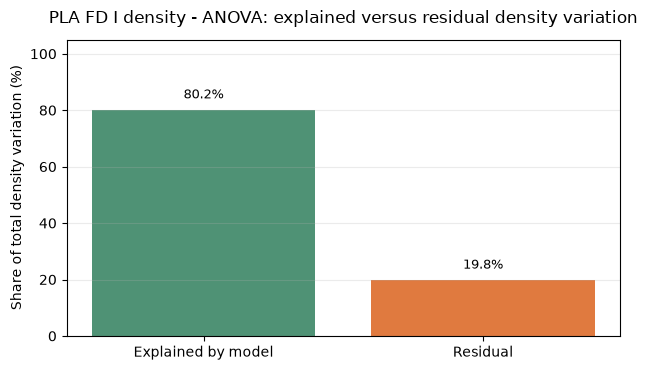

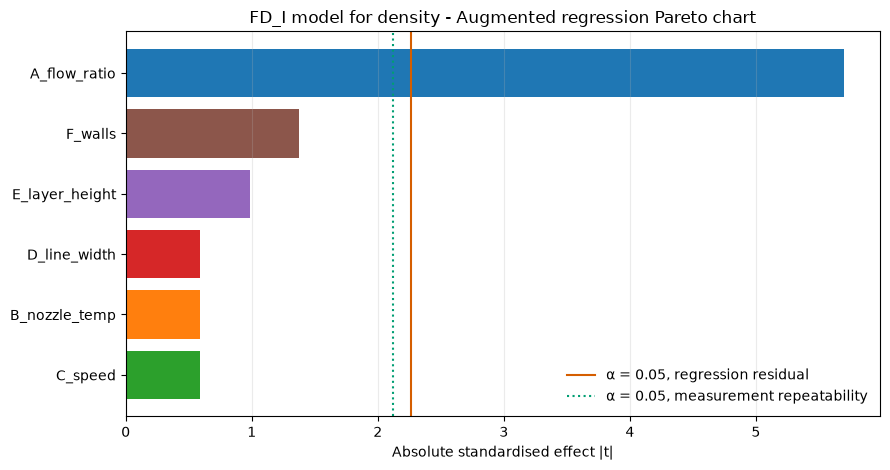

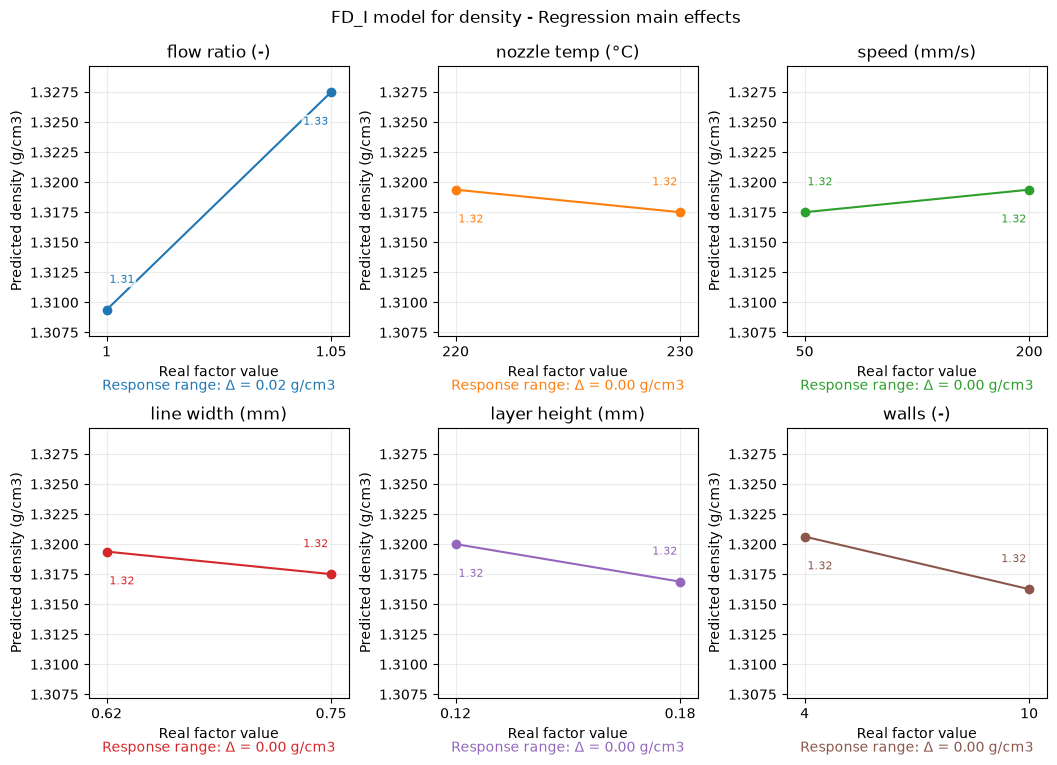

In [17]:
plt.close("all")

FD_I_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
    "F_walls",
]

FD_I_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
    "F_walls": ("A_flow_ratio", "C_speed"),  # F = AC
}

if "fd_I_hydrostatic_result_matrices" not in globals():
    fd_I_hydrostatic_result_matrices = {}
    for response_name in ["volume_cm3", "density_g_cm3"]:
        response_col = f"{response_name}_mean"
        fd_I_hydrostatic_result_matrices[response_name] = build_result_matrix(
            fd_I_coded_df,
            fd_I_hydrostatic_tables[response_name][["run", response_col]],
            response=response_col,
        )

fd_I_mass_regression_model = fit_main_effect_screening_model(
    mass_result_matrix_I,
    response="mass_mean_g",
    factor_cols=FD_I_FACTOR_COLUMNS,
)

display(fd_I_mass_regression_model["info_df"].round(4))
fd_I_mass_replicate_observations, fd_I_mass_pure_error_groups, fd_I_mass_pure_error_summary = (
    calculate_pure_error_from_replicates(
        mass_result_matrix_I,
        response="mass_mean_g",
        factor_cols=FD_I_FACTOR_COLUMNS,
        repeat_measurements_g=fd_I_repeat_mass_measurements_g,
    )
)
display(fd_I_mass_pure_error_groups.round(4))
display(fd_I_mass_pure_error_summary.round(4))
display(build_error_comparison_table(
    fd_I_mass_regression_model,
    fd_I_mass_pure_error_summary,
).round(4))
fd_I_mass_anova_table = build_model_anova_table(fd_I_mass_regression_model)
display(fd_I_mass_anova_table.round(4))
display(
    build_term_significance_table(
        fd_I_mass_regression_model,
        pure_error_summary=fd_I_mass_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    fd_I_mass_anova_table,
    response="mass_mean_g",
    experiment="FD_I model for mass",
)
plot_augmented_model_pareto(
    fd_I_mass_regression_model,
    experiment="FD_I model for mass",
    pure_error_summary=fd_I_mass_pure_error_summary,
)
plot_augmented_main_effects(
    fd_I_mass_regression_model,
    FD_I_LEVELS,
    experiment="FD_I model for mass",
    plot_label="Regression main effects",
)

fd_I_volume_result_matrix = fd_I_hydrostatic_result_matrices["volume_cm3"]
fd_I_density_result_matrix = fd_I_hydrostatic_result_matrices["density_g_cm3"]
FD_I_VOLUME_RESPONSE = "volume_cm3_mean"
FD_I_DENSITY_RESPONSE = "density_g_cm3_mean"

fd_I_volume_regression_model = fit_main_effect_screening_model(
    fd_I_volume_result_matrix,
    response=FD_I_VOLUME_RESPONSE,
    factor_cols=FD_I_FACTOR_COLUMNS,
)

fd_I_density_regression_model = fit_main_effect_screening_model(
    fd_I_density_result_matrix,
    response=FD_I_DENSITY_RESPONSE,
    factor_cols=FD_I_FACTOR_COLUMNS,
)

fd_I_volume_measurement_observations, fd_I_volume_measurement_groups, fd_I_volume_measurement_summary = (
    calculate_measurement_error_from_repeated_columns(
        fd_I_hydrostatic_tables["volume_cm3"],
        fd_I_hydrostatic_columns["volume_cm3"],
        FD_I_VOLUME_RESPONSE,
    )
)
fd_I_density_measurement_observations, fd_I_density_measurement_groups, fd_I_density_measurement_summary = (
    calculate_measurement_error_from_repeated_columns(
        fd_I_hydrostatic_tables["density_g_cm3"],
        fd_I_hydrostatic_columns["density_g_cm3"],
        FD_I_DENSITY_RESPONSE,
    )
)

fd_I_volume_anova_table = build_model_anova_table(fd_I_volume_regression_model)
display(fd_I_volume_anova_table.round(4))
display(fd_I_volume_measurement_groups.round(4))
display(fd_I_volume_measurement_summary.round(4))
display(build_error_comparison_table(
    fd_I_volume_regression_model,
    measurement_error_summary=fd_I_volume_measurement_summary,
).round(4))
display(build_term_significance_table(
    fd_I_volume_regression_model,
    measurement_error_summary=fd_I_volume_measurement_summary,
).round(4))
plot_model_anova(
    fd_I_volume_anova_table,
    response=FD_I_VOLUME_RESPONSE,
    experiment="FD_I model for volume",
)
plot_augmented_model_pareto(
    fd_I_volume_regression_model,
    experiment="FD_I model for volume",
    measurement_error_summary=fd_I_volume_measurement_summary,
)

plot_augmented_main_effects(
    fd_I_volume_regression_model,
    FD_I_LEVELS,
    experiment="FD_I model for volume",
    plot_label="Regression main effects",
)

fd_I_density_anova_table = build_model_anova_table(fd_I_density_regression_model)
display(fd_I_density_anova_table.round(4))
display(fd_I_density_measurement_groups.round(4))
display(fd_I_density_measurement_summary.round(4))
display(build_error_comparison_table(
    fd_I_density_regression_model,
    measurement_error_summary=fd_I_density_measurement_summary,
).round(4))
display(build_term_significance_table(
    fd_I_density_regression_model,
    measurement_error_summary=fd_I_density_measurement_summary,
).round(4))
plot_model_anova(
    fd_I_density_anova_table,
    response=FD_I_DENSITY_RESPONSE,
    experiment="PLA FD I density",
    variation_percent=True,
)
plot_augmented_model_pareto(
    fd_I_density_regression_model,
    experiment="FD_I model for density",
    measurement_error_summary=fd_I_density_measurement_summary,
)

plot_augmented_main_effects(
    fd_I_density_regression_model,
    FD_I_LEVELS,
    experiment="FD_I model for density",
    plot_label="Regression main effects",
)


#### FD_I Aliased Interaction Estimates


In [18]:
mass_interaction_matrix = add_interactions(mass_result_matrix_I)

#mass_interaction_matrix


In [19]:
FD_I_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
    "F_walls": ("A_flow_ratio", "C_speed"),  # F = AC
}

interaction_effects_I = compute_interaction_effects(
    mass_result_matrix_I,
    response="mass_mean_g",
    generators=FD_I_GENERATORS,
)

interaction_effects_I


,Interaction,Alias / generator note,Effect
7,B_nozzle_temp x E_layer_height,,7.000000e-01
11,C_speed x F_walls,,7.000000e-01
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-2.000000e-01
8,B_nozzle_temp x F_walls,,-1.000000e-01
10,C_speed x E_layer_height,,-1.000000e-01
3,A_flow_ratio x E_layer_height,,7.500000e-02
4,A_flow_ratio x F_walls,,2.500000e-02
9,C_speed x D_line_width,,-2.500000e-02
14,E_layer_height x F_walls,,2.500000e-02
6,B_nozzle_temp x D_line_width,,2.500000e-02


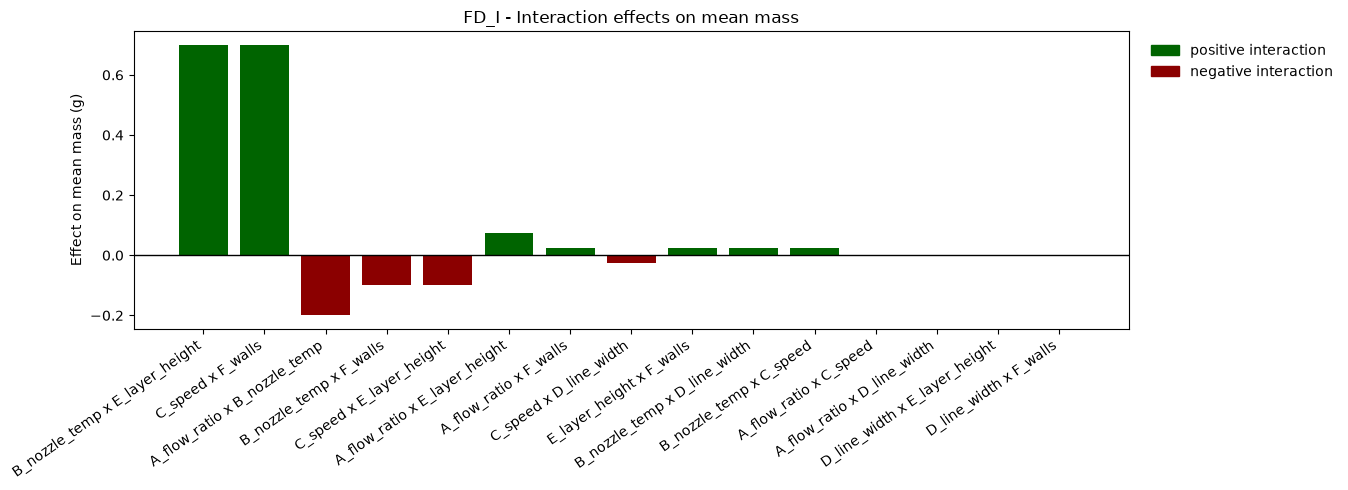

In [20]:
plot_interaction_effects(
    interaction_effects_I,
    experiment="FD_I",
    response="mass_mean_g",
)


#### FD_I Pairwise Interaction Plot Of Data Means


This plot shows the mean mass for each pair of coded factor levels. 
Non-parallel or crossing lines indicate a possible interaction pattern. 
Because FD_I is fractional, these visual interactions can still be aliased with generator relations such as `E = AB` and `F = AC`.


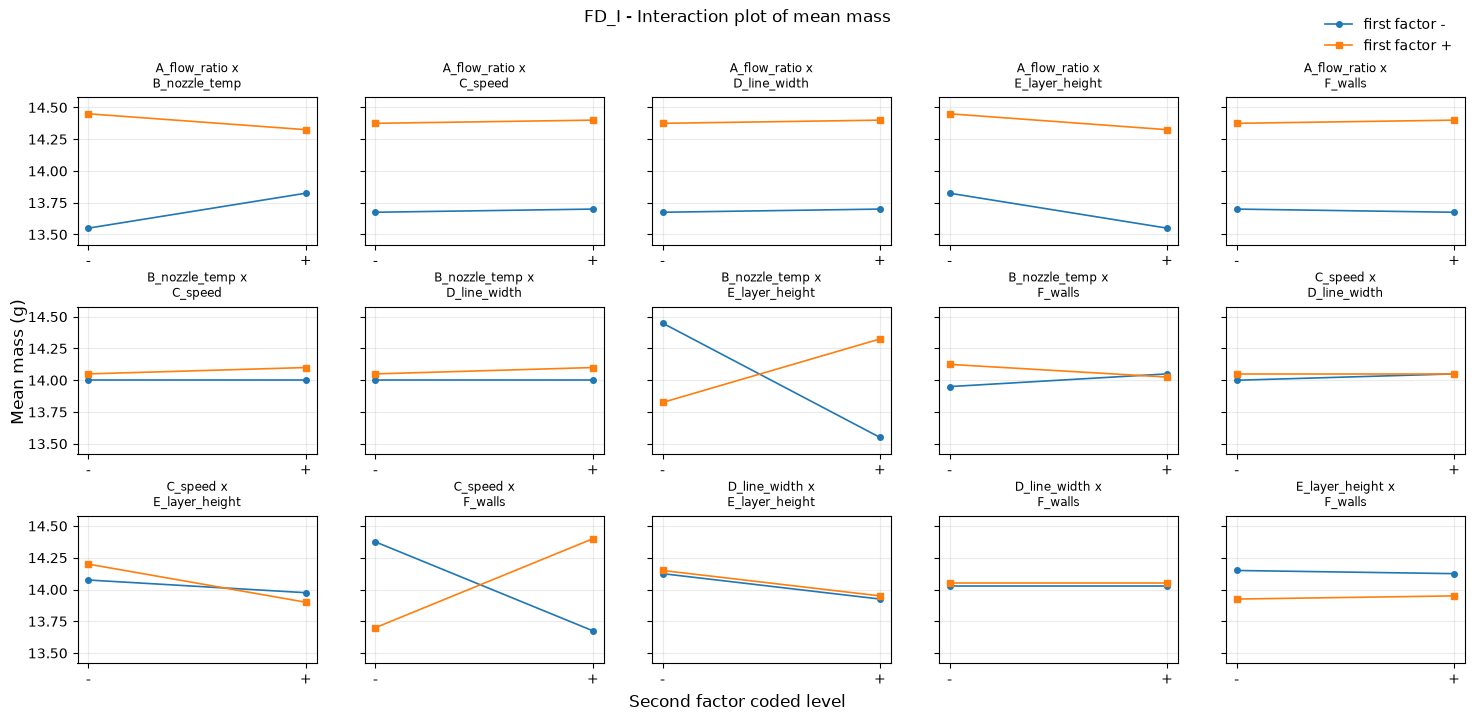

In [21]:
plot_interaction_mean_matrix(
    mass_result_matrix_I,
    response="mass_mean_g",
    experiment="FD_I",
)
